In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, load_npz
import joblib
import warnings
warnings.filterwarnings('ignore')

# ── Configurare device ────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}") 

INPUT_PATH = "/kaggle/input/notebooks/catalinagligor22/02-preprocessing/" 
OUTPUT_DIR = "/kaggle/working/"

# Imagini + masti
X_train_img = np.load(INPUT_PATH + 'X_train_img.npy')
X_val_img   = np.load(INPUT_PATH + 'X_val_img.npy')
X_test_img  = np.load(INPUT_PATH + 'X_test_img.npy')
y_train_img = np.load(INPUT_PATH + 'y_train_img.npy')
y_val_img   = np.load(INPUT_PATH + 'y_val_img.npy')
y_test_img  = np.load(INPUT_PATH + 'y_test_img.npy')

# Date clinice
df_train = pd.read_csv(INPUT_PATH + 'clinical_train.csv')
df_val   = pd.read_csv(INPUT_PATH + 'clinical_val.csv')
df_test  = pd.read_csv(INPUT_PATH + 'clinical_test.csv')

# Transformatoare
preprocessor = joblib.load(INPUT_PATH + 'preprocessor.pkl')
tfidf        = joblib.load(INPUT_PATH + 'tfidf_vectorizer.pkl')

print("Date încărcate cu succes!")
print(f"   Imagini train:  {X_train_img.shape}")
print(f"   Masti train:    {y_train_img.shape}")
print(f"   Pacienti train: {len(df_train)}")
print(f"   Pacienti val:   {len(df_val)}")


Device: cuda
PyTorch version: 2.10.0+cu128
Date încărcate cu succes!
   Imagini train:  (3080, 256, 256)
   Masti train:    (3080, 256, 256)
   Pacienti train: 47926
   Pacienti val:   10270


In [9]:
# Imagini + masti
X_train_img = np.load(INPUT_PATH + 'X_train_img.npy')
X_val_img   = np.load(INPUT_PATH + 'X_val_img.npy')
X_test_img  = np.load(INPUT_PATH + 'X_test_img.npy')
y_train_img = np.load(INPUT_PATH + 'y_train_img.npy')
y_val_img   = np.load(INPUT_PATH + 'y_val_img.npy')
y_test_img  = np.load(INPUT_PATH + 'y_test_img.npy')

# Date clinice
df_train = pd.read_csv(INPUT_PATH + 'clinical_train.csv')
df_val   = pd.read_csv(INPUT_PATH + 'clinical_val.csv')
df_test  = pd.read_csv(INPUT_PATH + 'clinical_test.csv')

# Transformatoare
preprocessor = joblib.load(INPUT_PATH + 'preprocessor.pkl')
tfidf        = joblib.load(INPUT_PATH + 'tfidf_vectorizer.pkl')

print(" Date încărcate cu succes!")
print(f"   Imagini train:  {X_train_img.shape}")
print(f"   Masti train:    {y_train_img.shape}")
print(f"   Pacienti train: {len(df_train)}")
print(f"   Pacienti val:   {len(df_val)}")

 Date încărcate cu succes!
   Imagini train:  (3080, 256, 256)
   Masti train:    (3080, 256, 256)
   Pacienti train: 47926
   Pacienti val:   10270


In [10]:
class CarotidDataset(Dataset):
    """
    Dataset custom PyTorch pentru imaginile ecografice carotidiene.
    Adaugă dimensiunea canalului cerută de CNN: (N, 256, 256) → (N, 1, 256, 256)
    """
    def __init__(self, images, masks):
        # Adaugă canal: (N, H, W) → (N, 1, H, W)
        self.images = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
        self.masks  = torch.tensor(masks,  dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]

# Creare DataLoader-e
train_dataset = CarotidDataset(X_train_img, y_train_img)
val_dataset   = CarotidDataset(X_val_img,   y_val_img)
test_dataset  = CarotidDataset(X_test_img,  y_test_img)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=16, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=16, shuffle=False, num_workers=2)

print(f"DataLoader creat!")
print(f"   Batch-uri train: {len(train_loader)}")
print(f"   Batch-uri val:   {len(val_loader)}")

DataLoader creat!
   Batch-uri train: 193
   Batch-uri val:   42


In [11]:
class DoubleConv(nn.Module):
    """Bloc de bază U-Net: Conv → BN → ReLU → Conv → BN → ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    """
    U-Net pentru segmentarea arterei carotide.
    Arhitectura clasică encoder-decoder cu skip connections.
    Input:  (B, 1, 256, 256)  — imagini grayscale
    Output: (B, 1, 256, 256)  — masca probabilistică
    """
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()

        # ── Encoder (coboară) ─────────────────────────────
        self.encoders  = nn.ModuleList()
        self.pools     = nn.ModuleList()
        in_ch = 1
        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f

        # ── Bottleneck ────────────────────────────────────
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        # ── Decoder (urcă) ────────────────────────────────
        self.upconvs   = nn.ModuleList()
        self.decoders  = nn.ModuleList()
        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, 2, stride=2))
            self.decoders.append(DoubleConv(f * 2, f))

        # ── Output ────────────────────────────────────────
        self.output = nn.Conv2d(features[0], 1, 1)

    def forward(self, x):
        skip_connections = []

        # Encoder
        for encoder, pool in zip(self.encoders, self.pools):
            x = encoder(x)
            skip_connections.append(x)
            x = pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]  # inversează ordinea

        # Decoder
        for upconv, decoder, skip in zip(self.upconvs, self.decoders, skip_connections):
            x    = upconv(x)
            x    = torch.cat([skip, x], dim=1)  # skip connection
            x    = decoder(x)

        return torch.sigmoid(self.output(x))

model = UNet().to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"U-Net creat! Parametri antrenabili: {total_params:,}")

U-Net creat! Parametri antrenabili: 31,036,481


In [12]:
def dice_loss(pred, target, smooth=1e-6):
    """
    Dice Loss — standard pentru segmentare medicală.
    Mai bun decât BCE pentru imagini cu dezechilibru (fundal >> obiect).
    """
    pred_flat   = pred.view(-1)
    target_flat = target.view(-1)
    intersection = (pred_flat * target_flat).sum()
    return 1 - (2. * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)

def combined_loss(pred, target):
    """BCE + Dice Loss combinate pentru stabilitate în antrenare."""
    bce  = nn.BCELoss()(pred, target)
    dice = dice_loss(pred, target)
    return bce + dice

def dice_score(pred, target, threshold=0.5):
    """Dice Score (metrica de evaluare, nu loss)."""
    pred_bin = (pred > threshold).float()
    smooth   = 1e-6
    intersection = (pred_bin * target).sum()
    return ((2. * intersection + smooth) / (pred_bin.sum() + target.sum() + smooth)).item()

# ── Optimizer și scheduler ───────────────────────────────
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

# ── Loop de antrenare ─────────────────────────────────────
EPOCHS = 30
train_losses, val_losses   = [], []
train_dices,  val_dices    = [], []
best_val_dice = 0.0

print(f"Incep antrenarea pe {EPOCHS} epoci...\n")

for epoch in range(EPOCHS):
    # ── TRAIN ──────────────────────────────────────────
    model.train()
    train_loss, train_dice = 0.0, 0.0

    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        preds = model(imgs)
        loss  = combined_loss(preds, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_dice += dice_score(preds.detach().cpu(), masks.cpu())

    # ── VALIDARE ───────────────────────────────────────
    model.eval()
    val_loss, val_dice = 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            preds = model(imgs)
            val_loss += combined_loss(preds, masks).item()
            val_dice += dice_score(preds.cpu(), masks.cpu())

    # Medii per epocă
    tl = train_loss / len(train_loader)
    vl = val_loss   / len(val_loader)
    td = train_dice / len(train_loader)
    vd = val_dice   / len(val_loader)

    train_losses.append(tl);  val_losses.append(vl)
    train_dices.append(td);   val_dices.append(vd)
    scheduler.step(vl)

    # Salvează cel mai bun model
    if vd > best_val_dice:
        best_val_dice = vd
        torch.save(model.state_dict(), OUTPUT_DIR + 'unet_best.pth')

    if (epoch + 1) % 5 == 0:
        print(f"Epoca {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {tl:.4f}/{vl:.4f} | "
              f"Dice: {td:.4f}/{vd:.4f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\n✅ Antrenare finalizata! Best Val Dice: {best_val_dice:.4f}")

Incep antrenarea pe 30 epoci...

Epoca 05/30 | Loss: 0.0647/0.0634 | Dice: 0.9489/0.9500 | LR: 0.001000
Epoca 10/30 | Loss: 0.0531/0.0502 | Dice: 0.9570/0.9593 | LR: 0.001000
Epoca 15/30 | Loss: 0.0513/0.0527 | Dice: 0.9583/0.9570 | LR: 0.001000
Epoca 20/30 | Loss: 0.0446/0.0461 | Dice: 0.9636/0.9623 | LR: 0.001000
Epoca 25/30 | Loss: 0.0432/0.0455 | Dice: 0.9647/0.9627 | LR: 0.000500
Epoca 30/30 | Loss: 0.0375/0.0433 | Dice: 0.9694/0.9647 | LR: 0.000500

✅ Antrenare finalizata! Best Val Dice: 0.9657


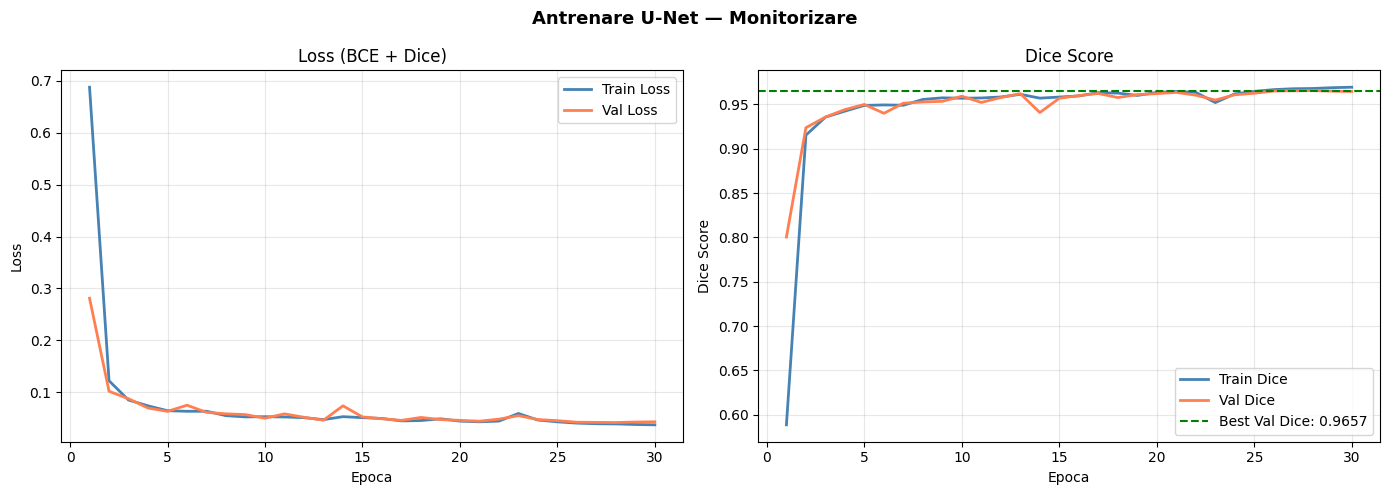

✅ Grafice antrenare salvate!


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Antrenare U-Net — Monitorizare', fontweight='bold', fontsize=13)

epochs_range = range(1, EPOCHS + 1)

# Loss
ax1.plot(epochs_range, train_losses, 'steelblue', label='Train Loss', linewidth=2)
ax1.plot(epochs_range, val_losses,   'coral',     label='Val Loss',   linewidth=2)
ax1.set_title('Loss (BCE + Dice)')
ax1.set_xlabel('Epoca')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Dice Score
ax2.plot(epochs_range, train_dices, 'steelblue', label='Train Dice', linewidth=2)
ax2.plot(epochs_range, val_dices,   'coral',     label='Val Dice',   linewidth=2)
ax2.axhline(y=best_val_dice, color='green', linestyle='--',
            label=f'Best Val Dice: {best_val_dice:.4f}')
ax2.set_title('Dice Score')
ax2.set_xlabel('Epoca')
ax2.set_ylabel('Dice Score')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'unet_training_curves.png', dpi=150)
plt.show()
print("✅ Grafice antrenare salvate!")

In [14]:
# Pregătire features clinice
numeric_features   = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categoric_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

X_train_tab = preprocessor.transform(df_train[numeric_features + categoric_features])
X_val_tab   = preprocessor.transform(df_val[numeric_features + categoric_features])

X_train_tfidf = tfidf.transform(df_train['risk_text'])
X_val_tfidf   = tfidf.transform(df_val['risk_text'])

X_train_clin = hstack([X_train_tab, X_train_tfidf])
X_val_clin   = hstack([X_val_tab,   X_val_tfidf])

y_train_clin = df_train['cardio'].values
y_val_clin   = df_val['cardio'].values

# ── Model 1: XGBoost ──────────────────────────────────────
print("Antrenez XGBoost...")
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    device='cpu'
)
xgb.fit(X_train_clin, y_train_clin,
        eval_set=[(X_val_clin, y_val_clin)],
        verbose=50)

xgb_acc = accuracy_score(y_val_clin, xgb.predict(X_val_clin))
xgb_f1  = f1_score(y_val_clin,       xgb.predict(X_val_clin))
xgb_auc = roc_auc_score(y_val_clin,  xgb.predict_proba(X_val_clin)[:,1])
print(f"\n XGBoost — Acc: {xgb_acc:.4f} | F1: {xgb_f1:.4f} | AUC: {xgb_auc:.4f}")

# ── Model 2: Logistic Regression (baseline) ──────────────
print("\nAntrenez Logistic Regression (baseline)...")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_clin, y_train_clin)

lr_acc = accuracy_score(y_val_clin, lr.predict(X_val_clin))
lr_f1  = f1_score(y_val_clin,       lr.predict(X_val_clin))
lr_auc = roc_auc_score(y_val_clin,  lr.predict_proba(X_val_clin)[:,1])
print(f" Logistic Regression — Acc: {lr_acc:.4f} | F1: {lr_f1:.4f} | AUC: {lr_auc:.4f}")

Antrenez XGBoost...
[0]	validation_0-logloss:0.67993
[50]	validation_0-logloss:0.54377
[100]	validation_0-logloss:0.54098
[150]	validation_0-logloss:0.54130
[200]	validation_0-logloss:0.54148
[250]	validation_0-logloss:0.54174
[299]	validation_0-logloss:0.54232

 XGBoost — Acc: 0.7334 | F1: 0.7183 | AUC: 0.8014

Antrenez Logistic Regression (baseline)...
 Logistic Regression — Acc: 0.7310 | F1: 0.7122 | AUC: 0.7935


In [15]:
results = pd.DataFrame({
    'Model':    ['XGBoost', 'Logistic Regression'],
    'Accuracy': [xgb_acc,  lr_acc],
    'F1-Score': [xgb_f1,   lr_f1],
    'AUC-ROC':  [xgb_auc,  lr_auc]
})

print("=" * 55)
print("TABEL COMPARATIV MODELE CLINICE")
print("=" * 55)
print(results.to_string(index=False))
print("=" * 55)
print(f"\nModel ales: XGBoost (AUC mai mare: {xgb_auc:.4f})")

TABEL COMPARATIV MODELE CLINICE
              Model  Accuracy  F1-Score  AUC-ROC
            XGBoost  0.733398  0.718313 0.801392
Logistic Regression  0.730964  0.712158 0.793468

Model ales: XGBoost (AUC mai mare: 0.8014)


In [16]:
# Salvare modele
torch.save(model.state_dict(),           OUTPUT_DIR + 'unet_final.pth')
joblib.dump(xgb,                         OUTPUT_DIR + 'xgboost_model.pkl')
joblib.dump(lr,                          OUTPUT_DIR + 'logistic_regression.pkl')

# Salvare rezultate comparatie
results.to_csv(OUTPUT_DIR + 'model_comparison.csv', index=False)

print("  Modele salvate in Output:")
print("   unet_best.pth           ← cel mai bun U-Net (din training)")
print("   unet_final.pth          ← U-Net final (ultima epoca)")
print("   xgboost_model.pkl       ← XGBoost antrenat")
print("   logistic_regression.pkl ← Baseline LR")
print("   model_comparison.csv    ← tabel comparativ")
print("   unet_training_curves.png ← grafice antrenare")

  Modele salvate in Output:
   unet_best.pth           ← cel mai bun U-Net (din training)
   unet_final.pth          ← U-Net final (ultima epoca)
   xgboost_model.pkl       ← XGBoost antrenat
   logistic_regression.pkl ← Baseline LR
   model_comparison.csv    ← tabel comparativ
   unet_training_curves.png ← grafice antrenare
